# Mini "Evolution Strategies at Scale": ES vs GRPO on one free GPU

A from-scratch, small-scale reimplementation of **Evolution Strategies at Scale: LLM Fine-Tuning Beyond Reinforcement Learning**
(Qiu et al., ICML 2026, arXiv:2509.24372, code: github.com/VsonicV/es-at-scale, original scripts in `archive/`).

The paper's claim: plain ES (no backprop, population of 30) can fine-tune **all** parameters of billion-parameter LLMs, and compared to RL it
1. handles outcome-only rewards on long reasoning outputs (Countdown),
2. is less prone to **reward hacking** and stays closer to the base model **without a KL penalty** (conciseness task),
3. is more stable across runs,
4. needs only inference-level GPU memory.

This notebook tests claims 2 and 4 head-to-head against GRPO (which I also write from scratch), and claim 1 at small scale.

| | Paper | This notebook |
|---|---|---|
| Model | Qwen2.5 0.5B–7B, Llama 1B–8B (conciseness: Qwen2.5-7B) | Qwen2.5-0.5B-Instruct (the paper's smallest), float32 |
| Population N | 30 | 16 (conciseness), 8 (Countdown) |
| Iterations | 1000 (conciseness), 500 (Countdown) | 60, 30 |
| Countdown data | 200 train / 2000 test prompts | 32 / 128 (same dataset file) |
| GRPO baseline | existing RL libraries | written from scratch here, same number of generated responses as ES |
| Hardware | multiple GPUs | 1× Kaggle T4 |

**Run time:** roughly 1.5 hours in total. Run Steps 0–A2 by hand first, then use *Save Version → Save & Run All*.

In [1]:
# Step 0 - check the GPU and library versions
import torch, transformers
print("torch", torch.__version__, "| transformers", transformers.__version__)
assert torch.cuda.is_available(), "No GPU. In Kaggle: Settings -> Accelerator -> GPU T4 x2 (or GPU P100)."
print("GPU:", torch.cuda.get_device_name(0))

torch 2.11.0+cu130 | transformers 5.20.2
GPU: Tesla T4


## Step 1 — Settings
Paper values are in the comments.

In [2]:
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"   # the paper's smallest model

# ---- Part A: conciseness, ES vs GRPO ----
CONC_MAX_NEW_TOKENS = 64        # paper: 100
ES_POP     = 16                 # N, population size (paper: 30)
ES_ITERS   = 60                 # paper: 1000
ES_SIGMA   = 1e-3               # sigma (paper: 1e-3)
ES_ALPHA   = 5e-4               # alpha (paper: 5e-4 = sigma / 2)
GRPO_GROUP = ES_POP             # samples per prompt, so one GRPO step generates as many responses as one ES iteration
GRPO_STEPS = ES_ITERS           # -> ES and GRPO see exactly the same number of generated responses
GRPO_LR    = 1e-5               # paper: 5e-6 over 1000 steps; we take far fewer steps
GRPO_BETAS = [0.0, 0.05]        # KL-penalty strengths (paper tried 0.0, 0.01, 0.0167, 0.0464, ... 1.0)
GRPO_MICRO_BATCH = 4            # lower this if you run out of GPU memory
EVAL_SAMPLES = 8                # sampled answers per held-out prompt (paper: 20)

# ---- Part B: Countdown, ES only ----
RUN_COUNTDOWN     = True
CD_URL            = "https://raw.githubusercontent.com/VsonicV/es-at-scale/main/archive/countdown/data/countdown.json"
CD_TRAIN_N        = 32          # paper: first 200 prompts
CD_EVAL_N         = 128         # paper: last 2000 prompts
CD_MAX_NEW_TOKENS = 256         # paper: 1024
CD_POP            = 8           # paper: 30
CD_ITERS          = 30          # paper: 500
CD_EVAL_EVERY     = 10
CD_EVAL_BATCH     = 64

SEED = 0
import os
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

## Step 2 — The ES machinery (the paper's "tricks", one function each)

| Paper trick | Here |
|---|---|
| Noise retrieval with random seeds: store only the seed, regenerate ε on demand | `perturb`, `es_update` |
| Layer-level in-place perturbation and restoration: add σε, evaluate, subtract σε | `perturb(+σ)` … `perturb(−σ)` in `es_train` |
| Reward normalization: z-score inside each iteration | `es_train` |
| Greedy decoding: all exploration comes from the weights, none from sampling | `generate(..., sample=False)` |
| Decomposed update: apply the update layer by layer, seed by seed | `es_update` |
| Learning-rate digestion: the 1/σ factor is folded into α | update is `α · (1/N) Σ zₙ εₙ`, no `/σ` |
| Parallel evaluation of population members | not used (one GPU); members run one after another |

**A detail from the official code:** the original `es_fine-tuning_*.py` scripts reset the random generator to the *same* seed for every weight tensor.
So all tensors with the same shape (e.g. the q-projections of all 24 layers) received *identical* noise. The authors call this "partially correlated noise"
and added `*_iid.py` versions that use `seed + tensor_index`. This notebook uses the i.i.d. version.

**Why float32:** the paper runs in bf16, but a T4 has no fast bf16, and in 16-bit precision "add σε then subtract σε" doesn't cancel exactly.

In [3]:
# Step 2 - model loading, generation, log-probs and the ES optimizer
import re, gc, json, math, time, random, warnings
import numpy as np
from transformers import AutoModelForCausalLM, AutoTokenizer, GenerationConfig
transformers.logging.set_verbosity_error()
warnings.filterwarnings("ignore")

DEVICE = "cuda"
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
tok.padding_side = "left"
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
_eos = GenerationConfig.from_pretrained(MODEL_NAME).eos_token_id
_eos = _eos if isinstance(_eos, list) else [_eos]
STOP_IDS = torch.tensor(sorted(set(_eos) | {tok.eos_token_id, tok.pad_token_id}), device=DEVICE)

def load_model():
    return AutoModelForCausalLM.from_pretrained(MODEL_NAME).float().to(DEVICE).eval()

def free_gpu():
    gc.collect()
    torch.cuda.empty_cache()

@torch.no_grad()
def generate(m, prompts, max_new_tokens, sample=False, n=1):
    # Raw-text prompts (no chat template), like the paper's code.
    # sample=False: greedy (the paper's choice for ES). sample=True: draw from the model's own distribution (T=1).
    enc = tok(prompts, return_tensors="pt", padding=True).to(DEVICE)
    if sample:
        kw = dict(do_sample=True, temperature=1.0, top_p=1.0, top_k=0, repetition_penalty=1.0)
    else:
        kw = dict(do_sample=False)
    out = m.generate(**enc, max_new_tokens=max_new_tokens, num_return_sequences=n,
                     pad_token_id=tok.pad_token_id, **kw)
    plen = enc["input_ids"].shape[1]
    texts = tok.batch_decode(out[:, plen:], skip_special_tokens=True)
    return texts, out, enc["attention_mask"].repeat_interleave(n, dim=0), plen

def response_mask(resp):
    # 1 for real response tokens (up to and including the first stop token), 0 for padding after it
    stop = torch.isin(resp, STOP_IDS).long()
    return ((stop.cumsum(1) - stop) == 0).float()

def response_logprobs(m, seqs, prompt_mask, plen):
    # log pi(token) for each response token, as the model would have produced it during generation
    resp = seqs[:, plen:]
    mask = response_mask(resp)
    attn = torch.cat([prompt_mask, mask.long()], dim=1)
    pos = (attn.cumsum(1) - 1).clamp(min=0)                  # correct positions despite left padding
    logits = m(input_ids=seqs, attention_mask=attn, position_ids=pos).logits[:, plen - 1:-1].float()
    logp = torch.log_softmax(logits, dim=-1).gather(-1, resp.unsqueeze(-1)).squeeze(-1)
    return logp, mask

def k3_kl(logp_model, logp_base):
    # per-token KL estimate used in the paper (Schulman 2020): r - log r - 1, with r = p_base / p_model
    log_r = logp_base - logp_model
    return torch.exp(log_r) - log_r - 1

@torch.no_grad()
def perturb(m, seed, scale):
    # theta <- theta + scale * eps(seed), one tensor at a time; tensor i uses seed + i (i.i.d. noise)
    gen = torch.Generator(device=DEVICE)
    for i, p in enumerate(m.parameters()):
        gen.manual_seed(seed + i)
        p.add_(torch.randn(p.shape, generator=gen, device=DEVICE, dtype=p.dtype), alpha=scale)

@torch.no_grad()
def es_update(m, seeds, z, alpha):
    # decomposed update: theta <- theta + alpha * (1/N) * sum_n z_n * eps_n, layer by layer, seed by seed
    gen = torch.Generator(device=DEVICE)
    for i, p in enumerate(m.parameters()):
        update = torch.zeros_like(p)
        for seed, zn in zip(seeds, z):
            gen.manual_seed(seed + i)
            update.add_(torch.randn(p.shape, generator=gen, device=DEVICE, dtype=p.dtype), alpha=float(zn))
        p.add_(update, alpha=alpha / len(seeds))
        del update

def es_train(m, fitness, pop, iters, sigma, alpha, tag, responses_per_member, eval_fn=None, eval_every=0):
    seed_rng = np.random.default_rng(SEED)
    hist = {"tag": tag, "iters": [], "evals": []}
    if eval_fn:
        hist["evals"].append({"iter": 0, **eval_fn(m)})
        print(f"[{tag}] iter   0  EVAL {hist['evals'][-1]}")
    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for it in range(iters):
        seeds = [int(s) for s in seed_rng.integers(0, 2**30, size=pop)]
        rewards, infos = [], []
        for s in seeds:
            perturb(m, s, +sigma)                        # theta + sigma * eps_n
            r, info = fitness(m)
            perturb(m, s, -sigma)                        # restore theta
            rewards.append(r)
            infos.append(info)
        R = np.array(rewards, dtype=np.float64)
        updated = bool(R.std() > 0)                      # all equal -> all z = 0 -> nothing to learn
        if updated:
            z = (R - R.mean()) / (R.std() + 1e-8)
            es_update(m, seeds, z, alpha)
        rec = {"iter": it + 1, "responses": (it + 1) * pop * responses_per_member,
               "reward_mean": float(R.mean()), "reward_max": float(R.max()), "updated": updated}
        for k in infos[0]:
            rec[k] = float(np.mean([inf[k] for inf in infos]))
        hist["iters"].append(rec)
        eta = (time.time() - t0) / (it + 1) * (iters - it - 1) / 60
        print(f"[{tag}] iter {it + 1:3d}/{iters}  mean reward {R.mean():8.3f}  max {R.max():8.3f}"
              f"  updated={updated}  ~{eta:.0f} min left")
        if eval_fn and eval_every and ((it + 1) % eval_every == 0 or it + 1 == iters):
            hist["evals"].append({"iter": it + 1, **eval_fn(m)})
            print(f"[{tag}] iter {it + 1:3d}  EVAL {hist['evals'][-1]}")
    hist["peak_gpu_gb"] = torch.cuda.max_memory_allocated() / 1e9
    return hist

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

# Part A — Conciseness: ES vs GRPO (reward hacking and KL)

The paper's second experiment. Two training prompts, and a reward that only looks at **length**:
R = −|len(answer) − len(shortest correct answer)|. Nothing checks whether the answer is right.
So the reward can be hacked: answering "!" to "3 + 5" gets the same perfect score as "8".

What the paper found (Qwen2.5-7B): GRPO without a KL penalty sometimes collapsed into short nonsense, and it needed a well-tuned KL penalty β to stay sane.
ES had **no** KL term, yet stayed closer to the base model, showed no hacking, and varied far less across runs.

We measure, on 8 held-out prompts:
- **reward:** the conciseness reward, 0 is the best possible;
- **correct:** how often the answer is actually right (the reward never sees this);
- **short & wrong:** answers of at most 10 characters that are wrong. This is the hacking signal;
- **KL from base:** how far the fine-tuned model drifted from the original.

In [4]:
# Step A1 - the conciseness task, rewards and evaluation
import re

# ---------- Part A: conciseness (the paper's 2 training prompts) ----------
TRAIN_PROMPTS = ["Solve: 3 + 5 =", "If all birds can fly and penguins are birds, can penguins fly?"]
TRAIN_TARGETS = ["8", "No"]          # shortest correct answer for each training prompt

# Held-out prompts: my own, in the style of the paper's 8 eval prompts (e.g. capital of France -> Paris)
EVAL_SET = [
    ("What is the capital of France?", "Paris"),
    ("Solve: 7 + 6 =", "13"),
    ("Solve: 9 - 4 =", "5"),
    ("How many legs does a spider have?", "8"),
    ("What color is the sky on a clear day?", "Blue"),
    ("What is the opposite of hot?", "Cold"),
    ("If all cats are animals and Tom is a cat, is Tom an animal?", "Yes"),
    ("If no fish can walk and a salmon is a fish, can a salmon walk?", "No"),
]
EVAL_PROMPTS = [p for p, _ in EVAL_SET]
EVAL_TARGETS = [t for _, t in EVAL_SET]


def conc_reward(response, target):
    """The paper's conciseness reward: R = -|len(y) - len(s_k)| (string length; 0 is the best possible)."""
    return -abs(len(response.strip()) - len(target))


def is_correct(response, target):
    """Not used for training. Only used to detect reward hacking: short but wrong answers."""
    return re.search(rf"\b{re.escape(target.lower())}\b", response.lower()) is not None


# ---------- Part B: Countdown (same rules as the paper's countdown_task.py) ----------
def cd_format_reward(text):
    """text = '<think>' + completion. 1.0 for the full <think>...</think>\\n<answer>...</answer> format,
    otherwise 0.1 for a closed think block + 0.5 for an answer block."""
    text = text.rstrip()
    if re.match(r"^<think>.*?</think>\n<answer>.*?</answer>$", text, re.DOTALL):
        return 1.0
    reward = 0.0
    if re.search(r"<think>.*?</think>", text, re.DOTALL):
        reward += 0.1
    if re.search(r"<answer>.*?</answer>", text, re.DOTALL):
        reward += 0.5
    return reward


def cd_answer_reward(completion, numbers, target):
    """1.0 if the last <answer> uses every given number exactly once and evaluates to the target."""
    answers = re.findall(r"<answer>(.*?)</answer>", completion, re.DOTALL)
    if not answers:
        return 0.0
    expr = answers[-1].strip()
    if not expr or not re.fullmatch(r"[0-9+\-*/() ]+", expr) or "**" in expr:   # no '**': 83**78**39 would hang
        return 0.0
    if sorted(int(n) for n in re.findall(r"\d+", expr)) != sorted(int(n) for n in numbers):
        return 0.0
    try:
        return 1.0 if abs(float(eval(expr, {"__builtins__": None}, {})) - float(target)) < 1e-5 else 0.0
    except Exception:
        return 0.0


def cd_rewards(items, completions):
    fmt = [cd_format_reward("<think>" + c) for c in completions]
    ans = [cd_answer_reward(c, it["numbers"], it["target"]) for c, it in zip(completions, items)]
    return fmt, ans


def conc_fitness(m):
    texts, *_ = generate(m, TRAIN_PROMPTS, CONC_MAX_NEW_TOKENS)          # greedy, like the paper
    return float(np.mean([conc_reward(x, t) for x, t in zip(texts, TRAIN_TARGETS)])), {}

@torch.no_grad()
def eval_conciseness(m, label):
    greedy, *_ = generate(m, EVAL_PROMPTS, CONC_MAX_NEW_TOKENS)
    torch.manual_seed(SEED)
    texts, seqs, pmask, plen = generate(m, EVAL_PROMPTS, CONC_MAX_NEW_TOKENS, sample=True, n=EVAL_SAMPLES)
    targets = [t for t in EVAL_TARGETS for _ in range(EVAL_SAMPLES)]
    kl_sum, n_tok = 0.0, 0.0
    for i in range(0, len(texts), 16):
        lp_m, mask = response_logprobs(m, seqs[i:i + 16], pmask[i:i + 16], plen)
        lp_b, _ = response_logprobs(base, seqs[i:i + 16], pmask[i:i + 16], plen)
        kl_sum += (k3_kl(lp_m, lp_b) * mask).sum().item()
        n_tok += mask.sum().item()
    return {"label": label,
            "reward": float(np.mean([conc_reward(x, t) for x, t in zip(texts, targets)])),
            "correct": float(np.mean([is_correct(x, t) for x, t in zip(texts, targets)])),
            "short_and_wrong": float(np.mean([len(x.strip()) <= 10 and not is_correct(x, t)
                                              for x, t in zip(texts, targets)])),
            "kl": kl_sum / max(n_tok, 1.0),
            "avg_chars": float(np.mean([len(x.strip()) for x in texts])),
            "greedy": greedy}

def show(r):
    print(f"--- {r['label']}: reward {r['reward']:.1f} | correct {r['correct']:.0%} | short&wrong "
          f"{r['short_and_wrong']:.0%} | KL {r['kl']:.3f} | avg {r['avg_chars']:.0f} chars")
    for (p, t), g in zip(EVAL_SET, r["greedy"]):
        print(f"   {p!r:68} -> {g.strip()[:70]!r}")

In [5]:
# Step A2 - load the frozen base model (the KL reference) and see how it answers
base = load_model()
base.requires_grad_(False)
conc_results = [eval_conciseness(base, "Base model")]
show(conc_results[0])

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

--- Base model: reward -247.5 | correct 67% | short&wrong 0% | KL 0.000 | avg 250 chars
   'What is the capital of France?'                                     -> 'The capital of France is Paris. \n\nTo verify this, I will use a simple '
   'Solve: 7 + 6 ='                                                     -> '? To solve the equation \\( 7 + 6 \\), you simply add the two numbers to'
   'Solve: 9 - 4 ='                                                     -> '5 + x\n\nTo solve the equation \\(9 - 4 = 5 + x\\), follow these steps:\n\n1'
   'How many legs does a spider have?'                                  -> 'A spider has eight legs. This is because spiders are arachnids, and al'
   'What color is the sky on a clear day?'                              -> 'The sky appears blue because it reflects sunlight. When light enters t'
   'What is the opposite of hot?'                                       -> 'The opposite of "hot" is "cold". \n\nTo explain this in more detail:\n\n1.'
   'If all

## Step A3 — ES on the conciseness task
Greedy decoding, reward = average conciseness reward on the 2 training prompts, **no KL penalty**.

In [6]:
# Step A3 - ES run
model = load_model()
es_conc = es_train(model, conc_fitness, ES_POP, ES_ITERS, ES_SIGMA, ES_ALPHA, "ES",
                   responses_per_member=len(TRAIN_PROMPTS))
r = eval_conciseness(model, "ES")
r["peak_gpu_gb"] = es_conc["peak_gpu_gb"]
conc_results.append(r)
show(r)
del model
free_gpu()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[ES] iter   1/60  mean reward -253.031  max -188.000  updated=True  ~31 min left
[ES] iter   2/60  mean reward -227.281  max -173.000  updated=True  ~31 min left
[ES] iter   3/60  mean reward -246.719  max -193.500  updated=True  ~30 min left
[ES] iter   4/60  mean reward -244.406  max -197.500  updated=True  ~30 min left
[ES] iter   5/60  mean reward -231.375  max -189.000  updated=True  ~29 min left
[ES] iter   6/60  mean reward -222.594  max -167.000  updated=True  ~28 min left
[ES] iter   7/60  mean reward -233.312  max -176.500  updated=True  ~28 min left
[ES] iter   8/60  mean reward -212.625  max -103.500  updated=True  ~27 min left
[ES] iter   9/60  mean reward -239.438  max -200.500  updated=True  ~27 min left
[ES] iter  10/60  mean reward -248.562  max -176.500  updated=True  ~26 min left
[ES] iter  11/60  mean reward -223.062  max -164.000  updated=True  ~26 min left
[ES] iter  12/60  mean reward -213.938  max -177.000  updated=True  ~25 min left
[ES] iter  13/60  mean rewar

## Step A4 — GRPO from scratch, for comparison
For each prompt, sample a group of G answers. Each answer's advantage is its reward relative to its group: Aᵢ = (Rᵢ − mean) / std.
Then take a gradient step on

  loss = − mean over tokens of [ Aᵢ · log π(token) ]  +  β · KL(π ‖ π_base)

We do one update per batch of fresh samples, so the PPO-style ratio is exactly 1 and clipping never triggers.
GRPO **needs** sampling, because without it every member of a group would be identical. ES uses greedy decoding instead.
Both methods get the same number of generated responses.

In [7]:
# Step A4 - GRPO training loop, then one run per beta
def grpo_train(beta, tag):
    m = load_model()
    opt = torch.optim.AdamW(m.parameters(), lr=GRPO_LR, weight_decay=0.0)
    targets = [t for t in TRAIN_TARGETS for _ in range(GRPO_GROUP)]
    n_resp = len(targets)
    hist = {"tag": tag, "iters": []}
    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for step in range(GRPO_STEPS):
        torch.manual_seed(SEED * 100_000 + step)
        texts, seqs, pmask, plen = generate(m, TRAIN_PROMPTS, CONC_MAX_NEW_TOKENS, sample=True, n=GRPO_GROUP)
        R = torch.tensor([conc_reward(x, t) for x, t in zip(texts, targets)], dtype=torch.float32, device=DEVICE)
        Rg = R.view(len(TRAIN_PROMPTS), GRPO_GROUP)
        adv = ((Rg - Rg.mean(1, keepdim=True)) / (Rg.std(1, keepdim=True) + 1e-4)).view(-1)
        opt.zero_grad(set_to_none=True)
        kl_sum, tok_sum = 0.0, 0.0
        for i in range(0, n_resp, GRPO_MICRO_BATCH):
            sl = slice(i, i + GRPO_MICRO_BATCH)
            logp, mask = response_logprobs(m, seqs[sl], pmask[sl], plen)
            per_token = -adv[sl].unsqueeze(1) * logp            # push up answers that beat their group
            if beta > 0:
                with torch.no_grad():
                    logp_base, _ = response_logprobs(base, seqs[sl], pmask[sl], plen)
                kl = k3_kl(logp, logp_base)
                per_token = per_token + beta * kl                # pull back toward the base model
                kl_sum += (kl.detach() * mask).sum().item()
                tok_sum += mask.sum().item()
            seq_loss = (per_token * mask).sum(1) / mask.sum(1).clamp(min=1)
            (seq_loss.sum() / n_resp).backward()
        torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        opt.step()
        rec = {"iter": step + 1, "responses": (step + 1) * n_resp,
               "reward_mean": R.mean().item(), "reward_max": R.max().item()}
        if beta > 0:
            rec["kl_train"] = kl_sum / max(tok_sum, 1.0)
        hist["iters"].append(rec)
        eta = (time.time() - t0) / (step + 1) * (GRPO_STEPS - step - 1) / 60
        print(f"[{tag}] step {step + 1:3d}/{GRPO_STEPS}  mean reward {rec['reward_mean']:8.3f}"
              f"  max {rec['reward_max']:8.3f}  ~{eta:.0f} min left")
    hist["peak_gpu_gb"] = torch.cuda.max_memory_allocated() / 1e9
    m.zero_grad(set_to_none=True)
    del opt
    free_gpu()
    return m, hist

grpo_hists = []
for beta in GRPO_BETAS:
    tag = f"GRPO β={beta:g}"
    m, h = grpo_train(beta, tag)
    r = eval_conciseness(m, tag)
    r["peak_gpu_gb"] = h["peak_gpu_gb"]
    conc_results.append(r)
    grpo_hists.append(h)
    show(r)
    del m
    free_gpu()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[GRPO β=0] step   1/60  mean reward -237.469  max -102.000  ~5 min left
[GRPO β=0] step   2/60  mean reward -222.469  max  -90.000  ~5 min left
[GRPO β=0] step   3/60  mean reward -197.188  max  -96.000  ~5 min left
[GRPO β=0] step   4/60  mean reward -180.875  max  -37.000  ~5 min left
[GRPO β=0] step   5/60  mean reward -180.844  max  -84.000  ~5 min left
[GRPO β=0] step   6/60  mean reward -131.625  max  -35.000  ~5 min left
[GRPO β=0] step   7/60  mean reward  -80.188  max  -35.000  ~5 min left
[GRPO β=0] step   8/60  mean reward  -53.625  max  -35.000  ~4 min left
[GRPO β=0] step   9/60  mean reward  -53.688  max  -34.000  ~4 min left
[GRPO β=0] step  10/60  mean reward  -46.375  max  -34.000  ~4 min left
[GRPO β=0] step  11/60  mean reward  -34.438  max   -8.000  ~4 min left
[GRPO β=0] step  12/60  mean reward  -13.219  max   -7.000  ~4 min left
[GRPO β=0] step  13/60  mean reward  -11.781  max   -7.000  ~3 min left
[GRPO β=0] step  14/60  mean reward  -11.562  max   -7.000  ~3 m

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[GRPO β=0.05] step   1/60  mean reward -237.469  max -102.000  ~6 min left
[GRPO β=0.05] step   2/60  mean reward -222.469  max  -90.000  ~6 min left
[GRPO β=0.05] step   3/60  mean reward -194.781  max  -89.000  ~6 min left
[GRPO β=0.05] step   4/60  mean reward -165.875  max  -84.000  ~6 min left
[GRPO β=0.05] step   5/60  mean reward -130.594  max  -85.000  ~6 min left
[GRPO β=0.05] step   6/60  mean reward -124.094  max  -68.000  ~6 min left
[GRPO β=0.05] step   7/60  mean reward -108.969  max  -65.000  ~5 min left
[GRPO β=0.05] step   8/60  mean reward  -79.938  max  -64.000  ~5 min left
[GRPO β=0.05] step   9/60  mean reward  -64.750  max  -45.000  ~5 min left
[GRPO β=0.05] step  10/60  mean reward  -57.938  max  -27.000  ~5 min left
[GRPO β=0.05] step  11/60  mean reward  -47.688  max  -18.000  ~4 min left
[GRPO β=0.05] step  12/60  mean reward  -38.594  max   -2.000  ~4 min left
[GRPO β=0.05] step  13/60  mean reward  -30.594  max   -2.000  ~4 min left
[GRPO β=0.05] step  14/60

## Step A5 — Results: reward vs KL (the paper's conciseness figure)

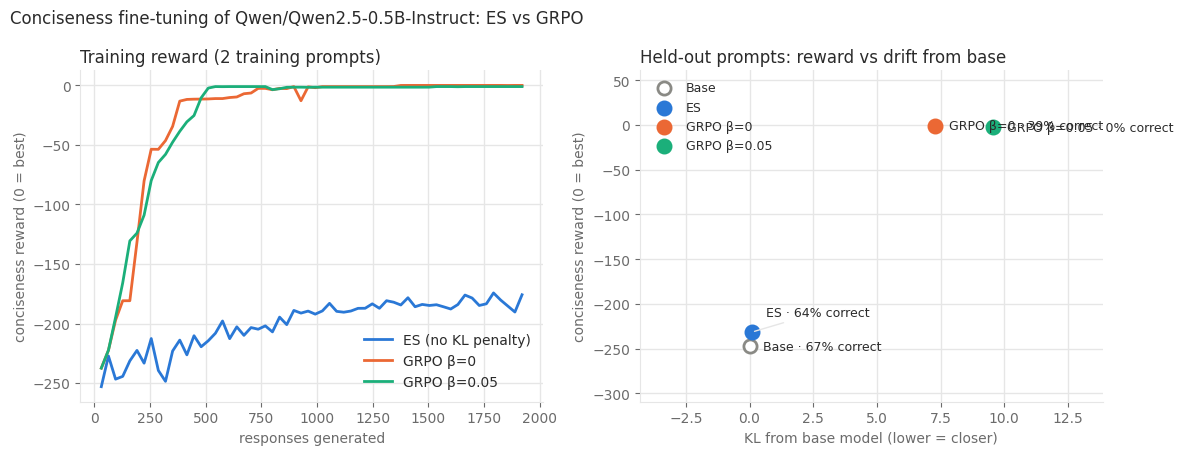

In [8]:
# Step A5 - plot: training curves and held-out reward vs KL
import matplotlib.pyplot as plt

INK, MUTED, GRID, BASE_GRAY = "#2b2b2b", "#6b6b6b", "#e6e6e6", "#8a8a85"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]     # ES first, then each GRPO run
runs = [(es_conc, "ES (no KL penalty)")] + [(h, h["tag"]) for h in grpo_hists]

def style(ax, title, xlabel, ylabel):
    ax.set_title(title, loc="left", color=INK, fontsize=12)
    ax.set_xlabel(xlabel, color=MUTED)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.grid(color=GRID, lw=1)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))

# left: training reward against the number of generated responses (same budget for every method)
for (h, label), color in zip(runs, SERIES):
    xs = [r["responses"] for r in h["iters"]]
    ys = [r["reward_mean"] for r in h["iters"]]
    ax1.plot(xs, ys, color=color, lw=2, label=label)
style(ax1, "Training reward (2 training prompts)", "responses generated", "conciseness reward (0 = best)")
ax1.legend(frameon=False, loc="best", labelcolor=INK)

# right: held-out reward vs KL from the base model, one point per final model
points = [(conc_results[0], BASE_GRAY, "Base")]
points += [(r, c, r["label"]) for r, c in zip(conc_results[1:], SERIES)]
for r, color, label in points:
    hollow = label == "Base"
    ax2.scatter(r["kl"], r["reward"], s=90, zorder=3, label=label,
                facecolors="white" if hollow else color, edgecolors=color, linewidths=2)
style(ax2, "Held-out prompts: reward vs drift from base", "KL from base model (lower = closer)",
      "conciseness reward (0 = best)")
ax2.margins(x=0.45, y=0.25)

# direct labels; points that sit on top of each other get their labels stacked instead of overlapping
xr = max(1e-9, max(r["kl"] for r, _, _ in points) - min(r["kl"] for r, _, _ in points))
yr = max(1e-9, max(r["reward"] for r, _, _ in points) - min(r["reward"] for r, _, _ in points))
placed = []
for r, color, label in sorted(points, key=lambda p: p[0]["reward"]):
    off = 0
    while any(abs(r["kl"] - x) / xr < 0.15 and abs(r["reward"] - y) / yr < 0.15 and abs(off - o) < 13
              for x, y, o in placed):
        off += 14
    placed.append((r["kl"], r["reward"], off))
    ax2.annotate(f"{label} · {r['correct']:.0%} correct", (r["kl"], r["reward"]), xytext=(10, off),
                 textcoords="offset points", va="center", color=INK, fontsize=9,
                 arrowprops=dict(arrowstyle="-", color=GRID, lw=1) if off else None)
ax2.legend(frameon=False, loc="best", labelcolor=INK, fontsize=9)

fig.suptitle(f"Conciseness fine-tuning of {MODEL_NAME}: ES vs GRPO", x=0.01, ha="left", color=INK)
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/conciseness_es_vs_grpo.png", dpi=150)
plt.show()

In [9]:
# Step A6 - the numbers + what each model actually says
print(f"{'':16s}{'reward':>8s}{'correct':>9s}{'short&wrong':>13s}{'KL':>8s}{'peak GPU':>10s}")
for r in conc_results:
    peak = f"{r['peak_gpu_gb']:.1f} GB" if "peak_gpu_gb" in r else "-"
    print(f"{r['label']:16s}{r['reward']:8.1f}{r['correct']:9.0%}{r['short_and_wrong']:13.0%}{r['kl']:8.3f}{peak:>10s}")
print("\nPeak GPU memory includes the frozen base model (~2 GB) kept for measuring KL.\n")
for r in conc_results:
    show(r)

                  reward  correct  short&wrong      KL  peak GPU
Base model        -247.5      67%           0%   0.000         -
ES                -231.4      64%           0%   0.091    5.1 GB
GRPO β=0            -0.7      39%          61%   7.275   11.9 GB
GRPO β=0.05         -2.5       0%         100%   9.563   11.9 GB

Peak GPU memory includes the frozen base model (~2 GB) kept for measuring KL.

--- Base model: reward -247.5 | correct 67% | short&wrong 0% | KL 0.000 | avg 250 chars
   'What is the capital of France?'                                     -> 'The capital of France is Paris. \n\nTo verify this, I will use a simple '
   'Solve: 7 + 6 ='                                                     -> '? To solve the equation \\( 7 + 6 \\), you simply add the two numbers to'
   'Solve: 9 - 4 ='                                                     -> '5 + x\n\nTo solve the equation \\(9 - 4 = 5 + x\\), follow these steps:\n\n1'
   'How many legs does a spider have?'               

# Part B — Countdown with ES (the paper's main task, scaled down)

Given numbers and a target, write an equation that hits the target using each number exactly once. The model reasons inside `<think>` and answers inside `<answer>`.
Reward = 0.1 × format + 1.0 × correct answer (same rules as the paper's `countdown_task.py`). The reward only arrives at the end of a long reasoning output,
which is the setting where the paper says token-level credit assignment makes RL struggle.

The paper's Table 1 for Qwen2.5-0.5B-Instruct: base 0.1% → ES 14.4% after 500 iterations with N=30 on 200 prompts. This run uses about 1/150 of that compute.
Expect the **format** part of the reward to improve first. Answer accuracy needs far more iterations.

In [10]:
# Step B1 - download the paper's Countdown data and set up the reward
if RUN_COUNTDOWN:
    if "base" in globals():
        del base                                   # Part B doesn't need the KL reference
    free_gpu()
    import urllib.request
    cd_path = f"{OUT_DIR}/countdown.json"
    if not os.path.exists(cd_path):
        urllib.request.urlretrieve(CD_URL, cd_path)
    with open(cd_path) as f:
        cd_data = json.load(f)
    cd_train, cd_eval = cd_data[:CD_TRAIN_N], cd_data[-CD_EVAL_N:]
    print(f"{len(cd_data)} problems; training on {len(cd_train)}, testing on {len(cd_eval)}")
    print("Example prompt:\n" + cd_train[0]["context"])

def cd_fitness(m):
    comps, *_ = generate(m, [it["context"] for it in cd_train], CD_MAX_NEW_TOKENS)   # greedy
    fmt, ans = cd_rewards(cd_train, comps)
    return (float(np.mean([0.1 * f + a for f, a in zip(fmt, ans)])),
            {"format": float(np.mean(fmt)), "answer": float(np.mean(ans))})

def cd_eval_fn(m):
    comps = []
    for i in range(0, len(cd_eval), CD_EVAL_BATCH):
        c, *_ = generate(m, [it["context"] for it in cd_eval[i:i + CD_EVAL_BATCH]], CD_MAX_NEW_TOKENS)
        comps += c
    fmt, ans = cd_rewards(cd_eval, comps)
    return {"accuracy": float(np.mean(ans)), "format": float(np.mean(fmt))}

def cd_example(m, k=0):
    c, *_ = generate(m, [cd_eval[k]["context"]], CD_MAX_NEW_TOKENS)
    fmt, ans = cd_rewards([cd_eval[k]], c)
    return f"numbers {cd_eval[k]['numbers']} target {cd_eval[k]['target']}  (format {fmt[0]}, correct {ans[0]})\n<think>{c[0]}"

2200 problems; training on 32, testing on 128
Example prompt:
You are a helpful assistant. You first think about the reasoning process in your mind and then provide the user with the answer.Using the numbers [44 19 35], create an equation that equals 98. You can use basic arithmetic operations (+, -, *, /) and each number can only be used once. Show your work in <think> </think> tags. And return the final answer in <answer> </answer> tags, for example <answer> (1 + 2) / 3 </answer>.Let me solve this step by step.
<think>


In [11]:
# Step B2 - ES on Countdown (the first EVAL line is the untrained model)
if RUN_COUNTDOWN:
    model = load_model()
    cd_before = cd_example(model)
    print("BEFORE training:\n" + cd_before + "\n")
    es_cd = es_train(model, cd_fitness, CD_POP, CD_ITERS, ES_SIGMA, ES_ALPHA, "ES Countdown",
                     responses_per_member=CD_TRAIN_N, eval_fn=cd_eval_fn, eval_every=CD_EVAL_EVERY)
    cd_after = cd_example(model)
    print("\nAFTER training:\n" + cd_after)
    del model
    free_gpu()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

BEFORE training:
numbers [75, 80, 17] target 12  (format 0.1, correct 0.0)
<think> 
To find an equation using the numbers 75, 80, and 17 that equals 12, we need to consider different combinations of addition, subtraction, multiplication, and division. Let's start by trying some simple cases:

1. 17 - 17 = 0
   This doesn't work because it's not equal to 12.

2. 75 - 80 = -5
   This also doesn't work because it's not equal to 12.

3. 75 * 17 = 1275
   This works! We have:
   75 * 17 = 1275

4. 80 + 17 = 97
   This doesn't work because it's not equal to 12.

So, one possible solution is: 75 * 17 = 1275

The final answer is: 75 * 17 = 1275
</think>

[ES Countdown] iter   0  EVAL {'iter': 0, 'accuracy': 0.0, 'format': 0.19140625}
[ES Countdown] iter   1/30  mean reward    0.036  max    0.053  updated=True  ~53 min left
[ES Countdown] iter   2/30  mean reward    0.039  max    0.053  updated=True  ~51 min left
[ES Countdown] iter   3/30  mean reward    0.035  max    0.056  updated=True  ~50 

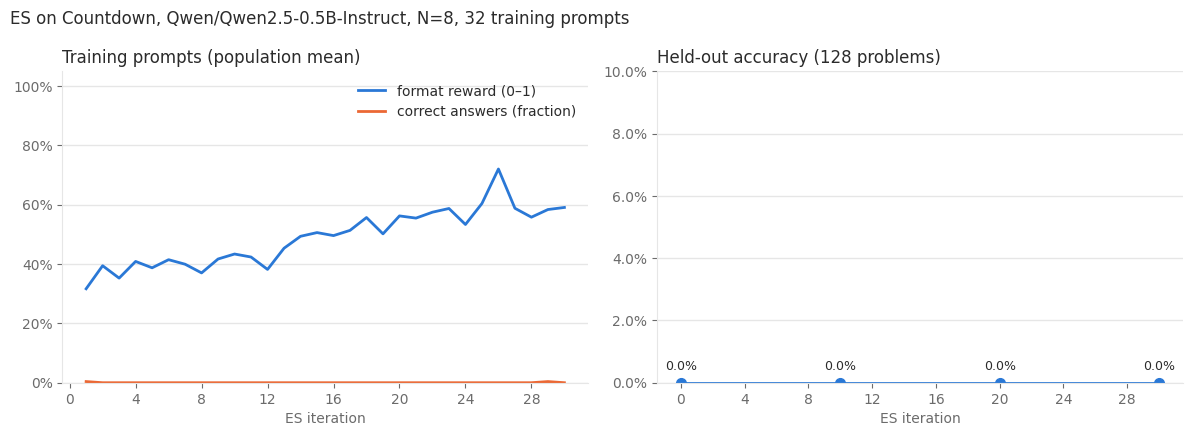

In [12]:
# Step B3 - plot Countdown: reward parts during training, and held-out accuracy
if RUN_COUNTDOWN:
    import matplotlib.pyplot as plt
    INK, MUTED, GRID = "#2b2b2b", "#6b6b6b", "#e6e6e6"
    BLUE, ORANGE = "#2a78d6", "#eb6834"

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
    its = [r["iter"] for r in es_cd["iters"]]
    ax1.plot(its, [r["format"] for r in es_cd["iters"]], color=BLUE, lw=2, label="format reward (0–1)")
    ax1.plot(its, [r["answer"] for r in es_cd["iters"]], color=ORANGE, lw=2, label="correct answers (fraction)")
    ax1.set_title("Training prompts (population mean)", loc="left", color=INK, fontsize=12)
    ax1.legend(frameon=False, loc="best", labelcolor=INK)

    ev_x = [e["iter"] for e in es_cd["evals"]]
    ev_y = [e["accuracy"] for e in es_cd["evals"]]
    ax2.plot(ev_x, ev_y, color=BLUE, lw=2, marker="o", ms=7)
    for x, y in zip(ev_x, ev_y):
        ax2.annotate(f"{y:.1%}", (x, y), xytext=(0, 9), textcoords="offset points", ha="center", color=INK, fontsize=9)
    ax2.set_title(f"Held-out accuracy ({CD_EVAL_N} problems)", loc="left", color=INK, fontsize=12)

    from matplotlib.ticker import PercentFormatter, MaxNLocator
    for ax in (ax1, ax2):
        ax.set_xlabel("ES iteration", color=MUTED)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_ylim(0, 1.05 if ax is ax1 else max(0.1, max(ev_y) * 1.4))
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
        ax.grid(axis="y", color=GRID, lw=1)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color(GRID)
        ax.tick_params(colors=MUTED)

    fig.suptitle(f"ES on Countdown, {MODEL_NAME}, N={CD_POP}, {CD_TRAIN_N} training prompts",
                 x=0.01, ha="left", color=INK)
    fig.tight_layout()
    fig.savefig(f"{OUT_DIR}/countdown_es.png", dpi=150)
    plt.show()

In [13]:
# Step C - save everything for the README
results = {"conciseness": conc_results, "es_conciseness": es_conc, "grpo": grpo_hists}
if RUN_COUNTDOWN:
    results.update({"es_countdown": es_cd, "countdown_before": cd_before, "countdown_after": cd_after})
with open(f"{OUT_DIR}/results.json", "w") as f:
    json.dump(results, f, indent=1, ensure_ascii=False)
print("saved", f"{OUT_DIR}/results.json")

saved /kaggle/working/results.json


## What to download
From the notebook's **Output** tab: `conciseness_es_vs_grpo.png`, `countdown_es.png`, `results.json`.
Then fill in `README_template.md` **in your own words**.